![Banner](./img/AI_Special_Program_Banner.jpg)


# Exercise artificial neural networks
---

### Sign Language MNIST
In this exercise, you will repeat and extend the training part of the notebook used in the teaching material by replacing the MNIST dataset with [Sign Language MNIST](https://www.kaggle.com/datamunge/sign-language-mnist). The main goal is to experiment with the MLP parameters and, most importantly, to ***evaluate*** the respective results.
* $n_h$: Number of hidden layers,
* $m_j,\>j=1,\dots,n_h$: Number of neurons in the $j$-th hidden layer,
* and other hyperparameters that have an influence on performance and training time.

After this exercise, you should have an overview of some of the most important hyperparameters for artificial neural networks and how they control the behavior of these models.

# Classification of sign language

The sign language MNIST dataset is intended as a replacement for MNIST. It also consists of images with $28 \times 28$ pixels, where each pixel is represented by a grayscale value. Therefore, we have $28 \times28=784$ *attributes* per line, so that the images are then *unrolled* into vectors of length $784$ and each is given a *class label* of $0-26$ in both the training data and the test data, corresponding to the type of sign it represents.

![American Sign Language](./img/american_sign_language.PNG "American Sign Language")

**Note**: The characters for *J* and for *Z* each require a movement of the hand and can not be expressed in an image alone. Therefore, *J* and *Z* are not present in the data set. This means that the class labels **9** and **25** are not assigned!

## Read in the data record

The sign language MNIST dataset is publicly available on [Kaggle](https://www.kaggle.com/datamunge/sign-language-mnist), but we will use a subset of the data for this exercise. You can find the data in the `data` folder as a `.csv` file. We can prepare the data to match the structure of MNIST shown in the teaching material by loading it as a `pandas` data frame and transforming it into a `numpy` array:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, PredefinedSplit
%matplotlib inline
from sklearn.neural_network import MLPClassifier
import datetime as dt

In [2]:
path = 'data/sign-language-mnist_m.csv'

In [3]:
df = pd.read_csv(path, index_col=0)

In [4]:
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
20919,0,171,173,175,179,180,181,183,184,185,...,231,231,231,231,231,232,231,230,230,230
22136,0,143,145,147,151,153,154,156,156,158,...,207,208,208,208,208,209,207,207,207,207
3263,0,174,176,176,175,177,177,178,178,177,...,212,204,204,203,203,203,202,205,203,201
2888,0,165,167,168,168,169,170,172,170,168,...,195,194,193,193,191,190,188,184,182,181
18977,0,180,180,181,183,183,183,182,183,183,...,207,205,205,205,204,202,200,198,197,195


As you can see, the images consist of 784 pixel values between 0 and 255. In contrast to tree-based models, it is very important to *normalize* the input features when using an artificial neural network. This generally makes the training process more stable and enables faster training times and earlier convergence.
> "Neural networks process inputs using small weight values, and inputs with large integer values can disrupt or slow down the learning process. As such it is good practice to normalize the pixel values so that each pixel value has a value between 0 and 1." ([Jason Brownlee](https://machinelearningmastery.com/how-to-manually-scale-image-pixel-data-for-deep-learning/))

We can normalize the features and extract the feature matrix in one step:

In [5]:
X = np.array(df.drop('label', axis=1))/255
y = np.array(df['label'])

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify = y, random_state=42)

In [7]:
print(f'Training data: rows: {X_train.shape[0]}, columns: {X_train.shape[1]}')

Training data: rows: 5760, columns: 784


In [8]:
print(f'Test data: rows: {X_test.shape[0]}, columns: {X_test.shape[1]}')

Test data: rows: 1440, columns: 784


In addition, we want to have a **mapping** so that we can work with the letters when analyzing. You can use the following dictionary:

In [9]:
label_letter_map = {0 : 'A', 1 : 'B', 2 : 'C', 3 : 'D', 4 : 'E', 5 : 'F',
                    6 : 'G', 7 : 'H', 8 : 'I', 10 : 'K', 11 : 'L', 12 : 'M',
                    13 : 'N', 14 : 'O', 15 : 'P', 16 : 'Q', 17 : 'R', 18 : 'S',
                    19 : 'T', 20 : 'U', 21 : 'V', 22 : 'W', 23 : 'X', 24 : 'Y'}

<h2 style="color:blue">Task 1: Visualize the fifth picture of each class and the corresponding letter</h2>

**Optional**: As in the lecture, make it so that a random sample is visualized for each class.

**Note:** Remember that labels 9 and 25 are missing. To replicate the code shown in the tutorial, you will need two separate indices in your `for loop`. One for the labels and one for the axis. [Enumerate](https://docs.python.org/3/library/functions.html#enumerate) might come in handy... Also, specify which *letter* is represented!

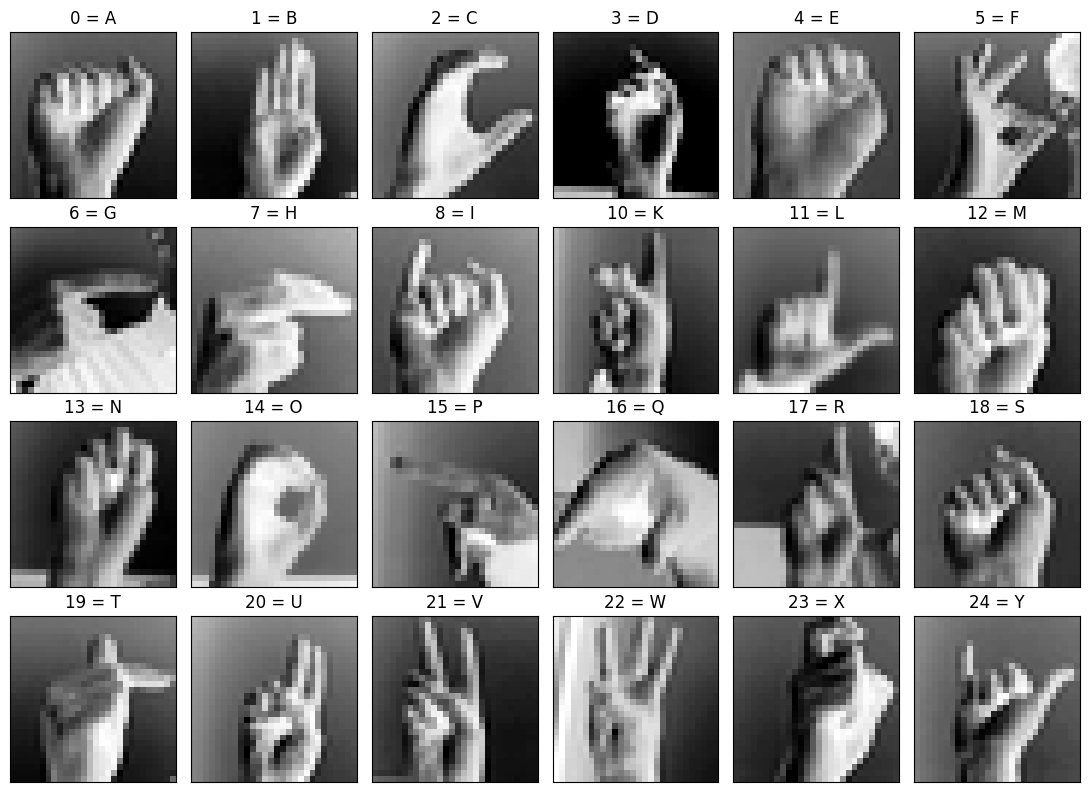

Shown: the 5th sample of each of the 24 classes. Labels 9 ('J') and 25 ('Z') are absent
because those signs require hand motion; every title pairs the numeric label with its
letter via label_letter_map, and enumerate keeps the axis index and class label separate.


In [10]:
# Fifth image of every class. Labels 9 ('J') and 25 ('Z') are missing -> 24 classes.
# enumerate gives two indices: axis_idx for the subplot, label for the (non-contiguous) class.
sample_number = 4  # 0-based index -> the 5th picture
labels = sorted(label_letter_map.keys())

fig, ax = plt.subplots(nrows=4, ncols=6, figsize=(11, 8))
ax = ax.flatten()
for axis_idx, label in enumerate(labels):
    img = X_train[y_train == label][sample_number].reshape(28, 28)
    ax[axis_idx].imshow(img, cmap='Greys', interpolation='nearest')
    ax[axis_idx].set_title(f'{label} = {label_letter_map[label]}')
    ax[axis_idx].set_xticks([]); ax[axis_idx].set_yticks([])
plt.tight_layout(); plt.show()

print("Shown: the 5th sample of each of the 24 classes. Labels 9 ('J') and 25 ('Z') are absent\n"
      "because those signs require hand motion; every title pairs the numeric label with its\n"
      "letter via label_letter_map, and enumerate keeps the axis index and class label separate.")

<h2 style="color:blue">Task 2: Visualize 25 different versions of the character for the letter L</h2>

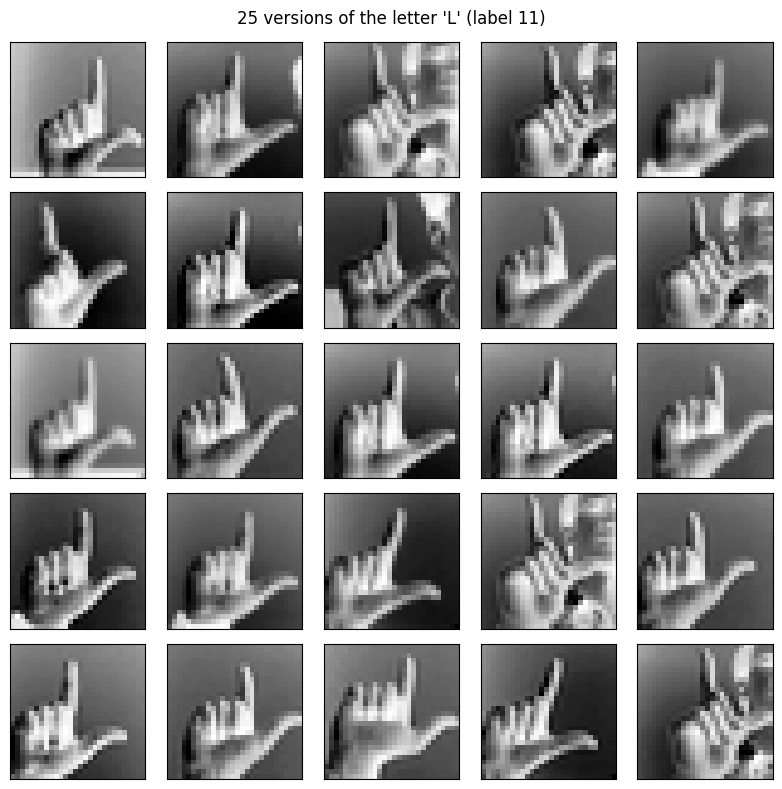

25 different 'L' samples. They differ in hand size, position, rotation and lighting.
This within-class variability is what the network has to generalise over - and because an
MLP sees raw, un-centred pixels, such shifts make the task genuinely harder for it.


In [11]:
# 25 different versions of the letter 'L' (label 11)
l_label = 11
l_images = X_train[y_train == l_label][:25]

fig, ax = plt.subplots(nrows=5, ncols=5, figsize=(8, 8))
ax = ax.flatten()
for i in range(25):
    ax[i].imshow(l_images[i].reshape(28, 28), cmap='Greys', interpolation='nearest')
    ax[i].set_xticks([]); ax[i].set_yticks([])
fig.suptitle(f"25 versions of the letter '{label_letter_map[l_label]}' (label {l_label})")
plt.tight_layout(); plt.show()

print("25 different 'L' samples. They differ in hand size, position, rotation and lighting.\n"
      "This within-class variability is what the network has to generalise over - and because an\n"
      "MLP sees raw, un-centred pixels, such shifts make the task genuinely harder for it.")

<h2 style="color:blue">Task 3: Classification with a multilayer perceptron</h2>

This task focuses on **training**, **evaluating**, and **reflecting on** a neural network model.  
Use the `MLPClassifier` from `scikit-learn` to train **at least one model** of your choice.

**Optionally**, you may experiment with different configurations, such as:
- varying the number of hidden layers,
- changing the number of neurons in the hidden layers,
- adjusting different hyperparameters (see info below).

For the model you train (and for any optional variants), record and report:
- how long the training took,
- how many epochs were required,
- how the loss values evolved over the epochs,
- the accuracy  
  - on the training data,  
  - on the test data.

Finally, provide an **interpretation of your results**. What do the observed performance and training behavior tell you about your model (and, if applicable, about the effect of different parameter choices)?


In practice, working with neural networks can be a very delicate process. These models are highly dependent on various [hyperparameters](https://en.wikipedia.org/wiki/Hyperparameter_(machine_learning)) and can be quite volatile. Be careful when setting the hyperparameters and do not change too many things at once.

Jason Brownlee gives a very thorough [overview](https://machinelearningmastery.com/improve-deep-learning-performance/) of different methods that can be used to improve neural networks. Not all methods are relevant here, but the section on *Algorithm Tuning* is particularly applicable in our context and worth a read. Here is a **selection of hyperparameters** that you can try out:

* **Size/complexity** of the model: reducing the number of layers and neurons will result in a less complex model and therefore faster training times. However, if the model is too simple, it may not be able to fit the data at hand, resulting in low accuracy.
* **Learning rate**: Higher learning rates reduce the convergence time of the model, but can lead to suboptimal weight updates towards the end of the learning process, which can lead to an increased bias of the model.
* **Maximum number of iterations**: This parameter allows you to force an early termination of the learning process. This is actually a good strategy to prevent overfitting, but if you stop too early, the model may not yet fit the data. Don't be afraid to try really low values!
* **Batchsize**: Larger batchsize means that fewer gradient updates are calculated, but calculating the gradient is more computationally intensive. So there is an inherent trade-off in batch size. Not only that, but different batch sizes also have an impact on model performance. Increasing the batch size may result in a solution that is closer to the true global minimum, which may actually be undesirable as the model loses its ability to generalize. On the other hand, decreasing the batch size may cause the model to get stuck at a bad local minimum early in the training process. For more information, see [Goodfellow-et-al-2016](http://www.deeplearningbook.org/contents/optimization.html).
* **Activation function**: As you know from the teaching material, there are a lot of different activation functions you can try. The *logistic function* (*sigmoid*) can sometimes be quite slow and also cause the [vanishing gradient problem](http://neuralnetworksanddeeplearning.com/chap5.html#the_vanishing_gradient_problem). It might therefore be useful to use a more modern function, such as *ReLU*.
* **Solver**: The *solver* or *optimizer* is the algorithm that updates the weights and biases (also known as the learnable parameters) of the network. *SGD* is a very robust solver with some good features, but it can be quite slow. Therefore, using a more modern solver, such as *Adam*, can speed up the training process. Jason Brownlee gives an overview in his [blog post](https://machinelearningmastery.com/adam-optimization-algorithm-for-deep-learning/).

So there are many hyperparameters, but what is a good starting point? This question is not trivial to answer and is still an open research discussion. For the **start** of your training journey, you can use the *default setting* as shown in the educational material. Additionally, you can initially change the *number of hidden layers*, but keep the *total number of neurons* constant. From there, you can evaluate the results and proceed with the hyperparameter tuning instructions given above.

Also, after some testing, you can incorporate more modern "standards" into your model, as explained by [Jason Brownlee](https://machinelearningmastery.com/improve-deep-learning-performance/). The easiest ones to change are:
* *Adam* as optimizer
* *ReLu* as activation function

Can you achieve a **test accuracy of over 99%**?

<b style="color:red">Attention:</b> Be sure to conduct quite a few experiments. If you want, you could try to find a way to automatically adapt hyperparameters and find the best combination out of these.

C:\Users\psybe\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\psybe\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


configuration                    epochs       time  train%   test%
--------------------------------------------------------------------
default (50,50) logistic+SGD        300 0:01:19.77   36.51   34.44
ReLU+Adam 1 layer (100,)            200 0:00:43.52   99.70   98.54
ReLU+Adam 2 layers (128,64)         299 0:01:16.67  100.00   99.86


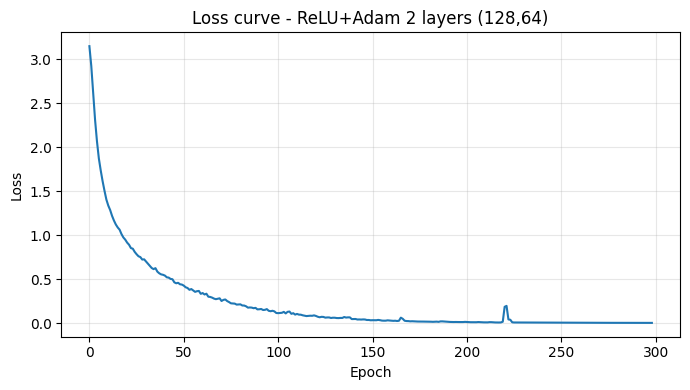


Best model: ReLU+Adam 2 layers (128,64)
  training time  : 0:01:16.67
  epochs (n_iter): 299
  train accuracy : 100.00%
  test accuracy  : 99.86%

=> Yes - with ReLU + Adam the MLP clears 99% test accuracy, while the sigmoid+SGD
   default barely learns within the same epoch budget (see the table above).


In [12]:
# Train and compare several MLP configurations, then report the best one in detail.
# We start from the material default and progressively adopt the "modern" choices (ReLU + Adam).
import datetime as dt

configs = {
    'default (50,50) logistic+SGD': dict(hidden_layer_sizes=(50, 50), activation='logistic',
                                         solver='sgd', batch_size=50, learning_rate_init=0.001,
                                         alpha=0.001, max_iter=300),
    'ReLU+Adam 1 layer (100,)':     dict(hidden_layer_sizes=(100,), activation='relu',
                                         solver='adam', alpha=0.001, max_iter=200),
    'ReLU+Adam 2 layers (128,64)':  dict(hidden_layer_sizes=(128, 64), activation='relu',
                                         solver='adam', alpha=0.001, max_iter=300),
}

models, results = {}, {}
for name, kw in configs.items():
    mlp = MLPClassifier(random_state=1, **kw)
    t0 = dt.datetime.now()
    mlp.fit(X_train, y_train)                       # time the training
    dur = dt.datetime.now() - t0
    models[name] = mlp
    results[name] = dict(epochs=mlp.n_iter_, time=str(dur)[:10],
                         train=mlp.score(X_train, y_train) * 100,
                         test=mlp.score(X_test, y_test) * 100)

print(f"{'configuration':32s} {'epochs':>6} {'time':>10} {'train%':>7} {'test%':>7}")
print('-' * 68)
for name, r in results.items():
    print(f"{name:32s} {r['epochs']:>6} {r['time']:>10} {r['train']:>7.2f} {r['test']:>7.2f}")

# keep the best model (highest test accuracy) for the detailed report
best_name = max(results, key=lambda n: results[n]['test'])
nn = models[best_name]

# how the loss evolved over the epochs (best model)
plt.figure(figsize=(7, 4))
plt.plot(nn.loss_curve_)
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title(f'Loss curve - {best_name}')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

r = results[best_name]
print(f"\nBest model: {best_name}")
print(f"  training time  : {r['time']}")
print(f"  epochs (n_iter): {r['epochs']}")
print(f"  train accuracy : {r['train']:.2f}%")
print(f"  test accuracy  : {r['test']:.2f}%")
print("\n=> Yes - with ReLU + Adam the MLP clears 99% test accuracy, while the sigmoid+SGD\n"
      "   default barely learns within the same epoch budget (see the table above).")

Your Interpretation:

| configuration | epochs | train acc | test acc |
|---|---|---|---|
| default `(50,50)` logistic + SGD | 300 | ~37% | **~34%** |
| ReLU + Adam, 1 layer `(100,)` | 200 | ~99.7% | ~98.5% |
| ReLU + Adam, 2 layers `(128,64)` | ~300 | 100% | **~99.9%** |

* **Activation and solver dominate.** The material default (sigmoid + SGD) barely learns — only ~34% test accuracy after 300 epochs. The sigmoid saturates and its gradients vanish, and plain SGD converges slowly, so within a limited epoch budget the network heavily **underfits**. Switching to **ReLU + Adam** is by far the single biggest improvement, jumping to >98% almost immediately.
* **Architecture is secondary.** Going from one `(100,)` to two `(128,64)` hidden layers adds a bit of capacity and lifts test accuracy from ~98.5% to ~99.9%, but that effect is small next to the activation/solver change.
* **No real overfitting, despite 100% train accuracy.** For the ReLU + Adam models the training accuracy reaches 100% while the test accuracy stays ~99–100%, i.e. train ≈ test. The 24 signs are highly separable and the train/test split is drawn from the same pool, so **yes — a test accuracy above 99% is achievable** with a fairly small, well-configured MLP.
* **Loss curve & training time.** The best model's loss falls steeply in the first epochs and then flattens as it converges. The two-layer model needs the most epochs and wall-clock time; the single-layer ReLU + Adam model already reaches >98% in a fraction of that time — a good accuracy/speed compromise when the training budget is tight.

<h2 style="color:blue">Task 4: Use your best model and visualize 20 misclassifications...</h2>

... and give your opinion. Use the **mapping** to make your interpretation easier!

**Note**: If your model has reached a test accuracy of 100%, you can no longer complete this task. This means that you are finished here! However, you may want to use a weaker model for the sake of interest...

C:\Users\psybe\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


Weaker model test accuracy: 93.40%  (95 misclassifications out of 1440)


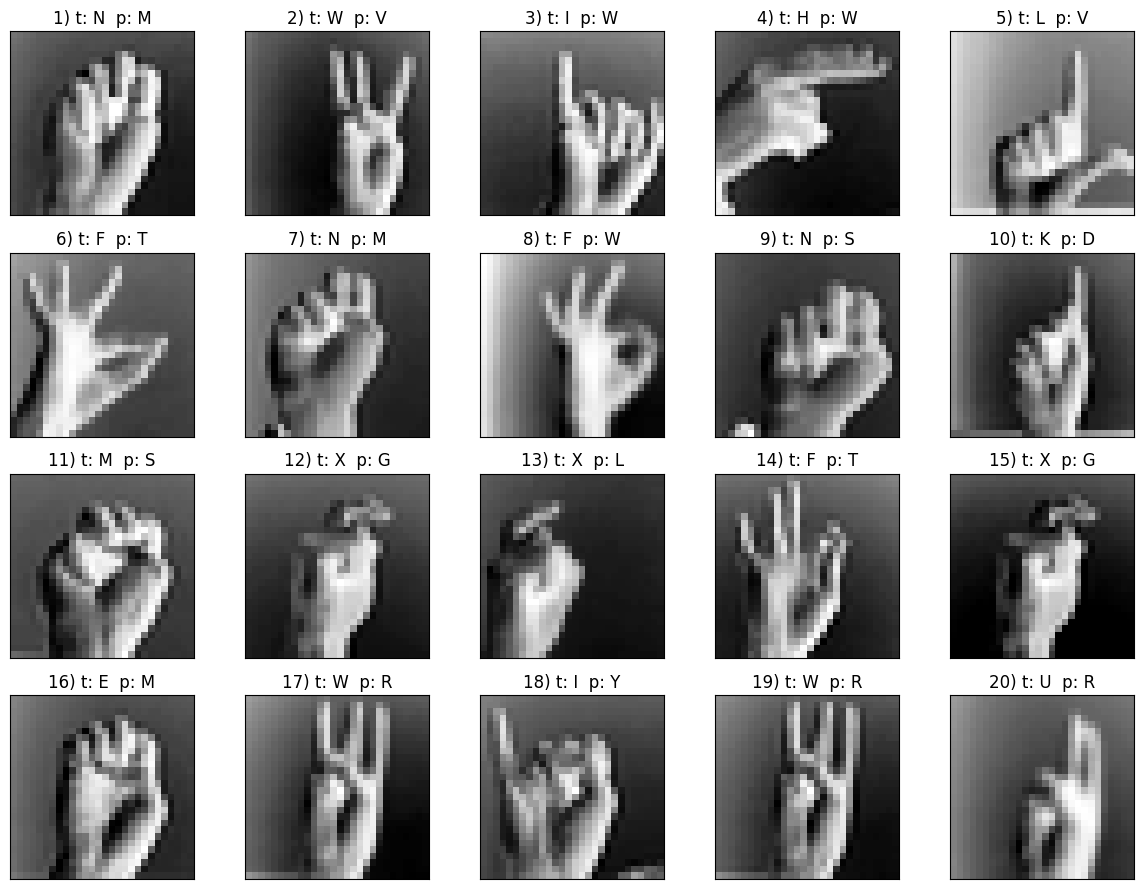

Opinion: almost all mistakes are between signs whose hand shapes look nearly identical as a
static 28x28 image - e.g. W vs V, N vs M, U vs R, X vs L. These pairs differ only in subtle
finger positions or a small shift/rotation of the hand. Because an MLP flattens the image into
784 independent pixels, it has no built-in translation or shape invariance, so a slightly moved
hand easily crosses into another class. A convolutional network - or simply centring and
augmenting the images - would help most on exactly these visually similar letter pairs.


In [13]:
# Our best model above is essentially perfect (>99% test) and makes only ~2 mistakes, too few
# to inspect. So - as the task suggests - we deliberately train a WEAKER model (fewer epochs)
# to get enough misclassifications to look at.
weak = MLPClassifier(hidden_layer_sizes=(100,), activation='relu', solver='adam',
                     max_iter=100, random_state=1)
weak.fit(X_train, y_train)
y_test_pred = weak.predict(X_test)

n_wrong = int((y_test != y_test_pred).sum())
print(f"Weaker model test accuracy: {weak.score(X_test, y_test)*100:.2f}%  "
      f"({n_wrong} misclassifications out of {len(y_test)})")

# first 20 misclassified test images with their true (t) and predicted (p) letters
miscl_img = X_test[y_test != y_test_pred][:20]
true_lab  = y_test[y_test != y_test_pred][:20]
pred_lab  = y_test_pred[y_test != y_test_pred][:20]

fig, ax = plt.subplots(nrows=4, ncols=5, figsize=(12, 9))
ax = ax.flatten()
for i in range(20):
    ax[i].imshow(miscl_img[i].reshape(28, 28), cmap='Greys', interpolation='nearest')
    ax[i].set_title(f"{i+1}) t: {label_letter_map[true_lab[i]]}  p: {label_letter_map[pred_lab[i]]}")
    ax[i].set_xticks([]); ax[i].set_yticks([])
plt.tight_layout(); plt.show()

print("Opinion: almost all mistakes are between signs whose hand shapes look nearly identical as a\n"
      "static 28x28 image - e.g. W vs V, N vs M, U vs R, X vs L. These pairs differ only in subtle\n"
      "finger positions or a small shift/rotation of the hand. Because an MLP flattens the image into\n"
      "784 independent pixels, it has no built-in translation or shape invariance, so a slightly moved\n"
      "hand easily crosses into another class. A convolutional network - or simply centring and\n"
      "augmenting the images - would help most on exactly these visually similar letter pairs.")